In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.preprocessing import RobustScaler
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
import seaborn as sns
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    train_test_split,
)
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
)
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
import numpy as np

In [5]:
class CustomNumericalImputer(BaseEstimator, TransformerMixin):
    def __init__(self,stratigy="median"):
        self.stratigy=stratigy

    def fit(self,x,y=None):
        x=np.asarray(x,dtype="float")
        if self.stratigy=="median":
            self.impute_=np.nanmedian(x,axis=0)
        elif self.stratigy=="mean":
            self.impute_=np.nanmean(x,axis=0)
        else:
            raise ValueError(
                "error choice between median,mean"
            )

        if np.isnan(self.impute_).any():
            raise ValueError("At least one column contains only NaN values.")
        return self

    def transform(self,x):
        x=np.asarray(x,dtype="float").copy()
        for i in range(x.shape[1]):
            mask=np.isnan(x[:,i])
            x[mask,i]=self.impute_[i]
        return x



In [6]:
def EDA(df):
    print("="*60)
    print("Shape")
    print("="*60)
    print(f"Rows:{df.shape[0]}")
    print(f"Columns:{df.shape[1]}")

    print("\n" + "=" * 60)
    print("Head")
    print("="*60)
    print(df.head())

    print("\n" + "=" * 60)
    print("Info")
    print("="*60)
    df.info()

    print("\n" + "=" * 60)
    print("Data Type")
    print("="*60)
    print(df.dtypes)

    print("\n" + "=" * 60)
    print("Missing Data")
    print("="*60)
    missing=pd.DataFrame({
        "Missing":df.isnull().sum(),
        "Percentage":df.isnull().sum()*100
    })
    print(missing[missing["Missing"]>0])

    print("\n" + "=" * 60)
    print("Duplicated")
    print("="*60)
    print(f"{df[df.duplicated(keep=False)]}")
    print(f"duplicate: {df.duplicated().sum()}")

    num_col=df.select_dtypes(include=["int64","float64"]).columns.tolist()
    cat_col=df.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

    print("\n" + "=" * 60)
    print("Numerical Columns")
    print("="*60)

    print(num_col)

    print("\n" + "=" * 60)
    print("Categorical Columns")
    print("="*60)

    print(cat_col)

    print("\n" + "=" * 60)
    print("Numerical Description")
    print("="*60)

    if len(num_col)>0:
        print(df[num_col].describe())

    print("\n" + "=" * 60)
    print("Categorical Description")
    print("="*60)

    if len(cat_col)>0:
        print(df[cat_col].describe())

    print("\n" + "=" * 60)
    print("Uniqe Value")
    print("="*60)

    uniqe=pd.DataFrame({
        "num_uniqe":df.nunique()
    })
    print(uniqe)

    print("\n" + "=" * 60)
    print("Value Count")
    print("="*60)

    for i in cat_col:
        print(f"----{i}----")
        print(df[i].value_counts(dropna=False).head(5))

        print("\n" + "=" * 60)
    print("13. SKEWNESS")
    print("=" * 60)

    if len(num_col) > 0:

        skewness = (
            df[num_col]
            .skew()
            .sort_values(ascending=False)
        )

        print(skewness)

data_path=r"C:\Users\mosa\Downloads\insurance (1).csv"
df=pd.read_csv(data_path)
EDA(df)


Shape
Rows:1338
Columns:7

Head
   age     sex     bmi  children smoker     region      charges
0   19  female  27.900         0    yes  southwest  16884.92400
1   18    male  33.770         1     no  southeast   1725.55230
2   28    male  33.000         3     no  southeast   4449.46200
3   33    male  22.705         0     no  northwest  21984.47061
4   32    male  28.880         0     no  northwest   3866.85520

Info
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB

Data Type
age           int64
sex          object
bmi    

In [7]:
df=df.drop_duplicates()

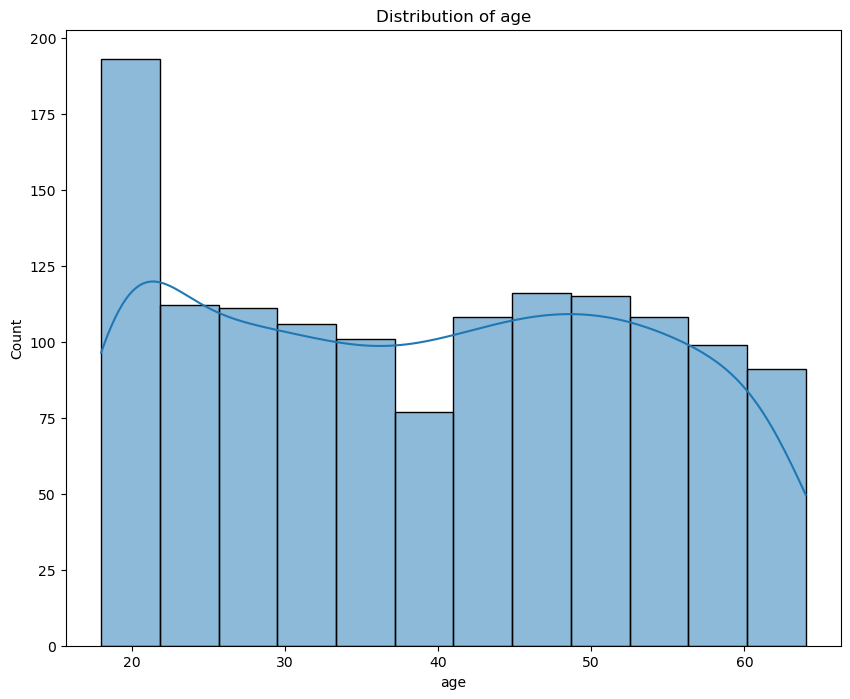

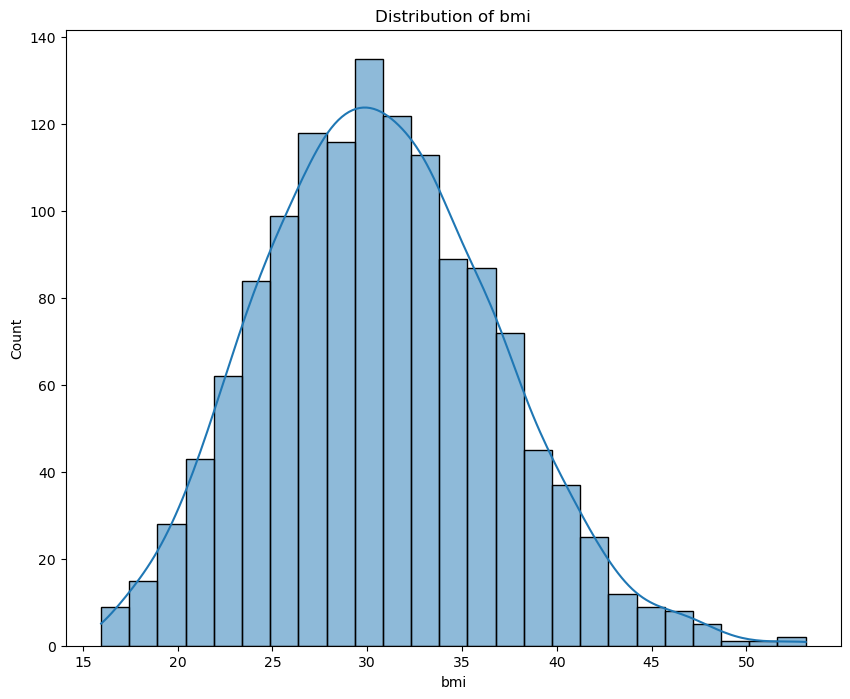

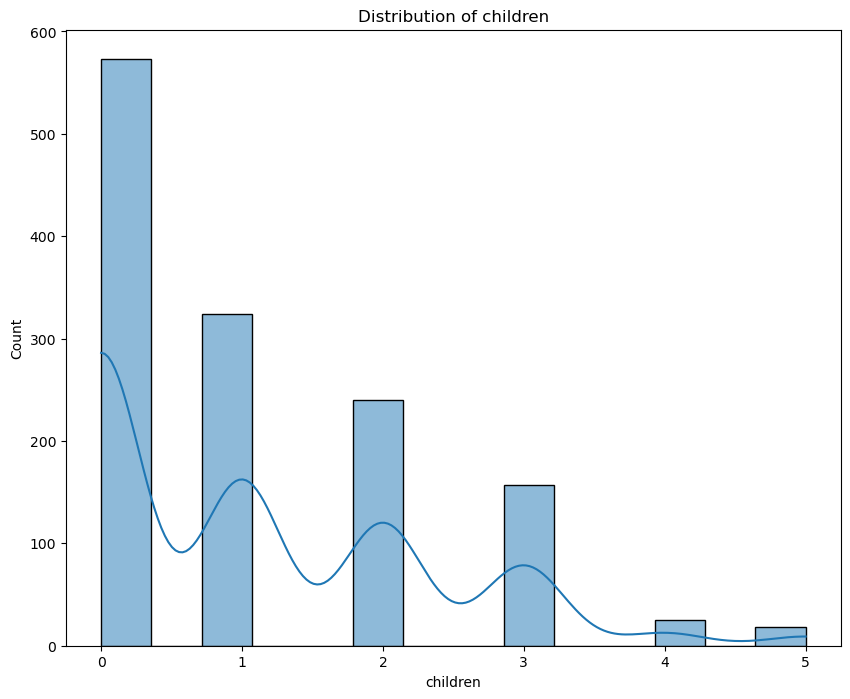

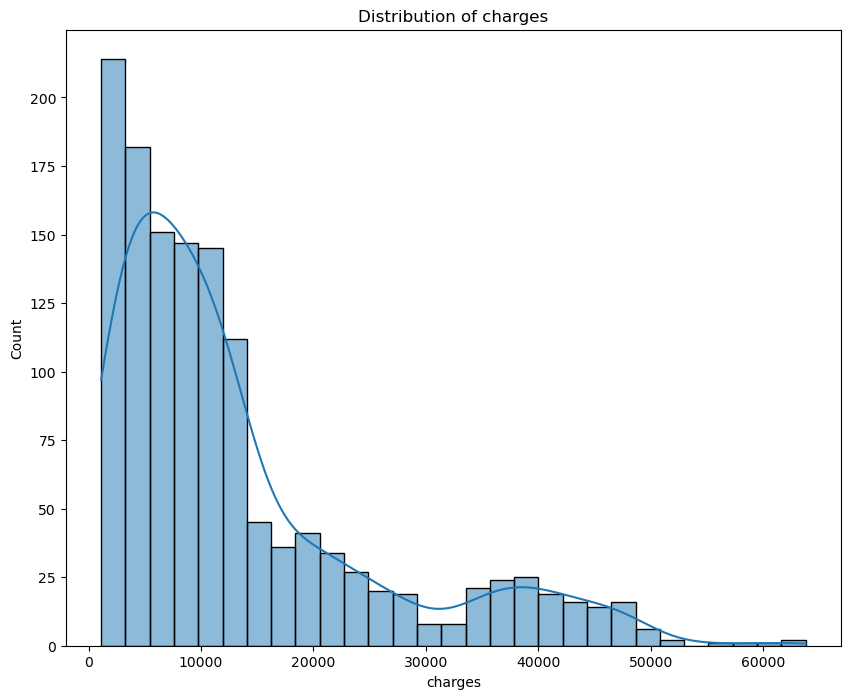

In [8]:
num_col=df.select_dtypes(include=["int64","float64"]).columns

for i in num_col:
    plt.figure(figsize=(10,8))
    sns.histplot(data=df,x=i,kde=True)
    plt.title(f"Distribution of {i}")
    plt.show()

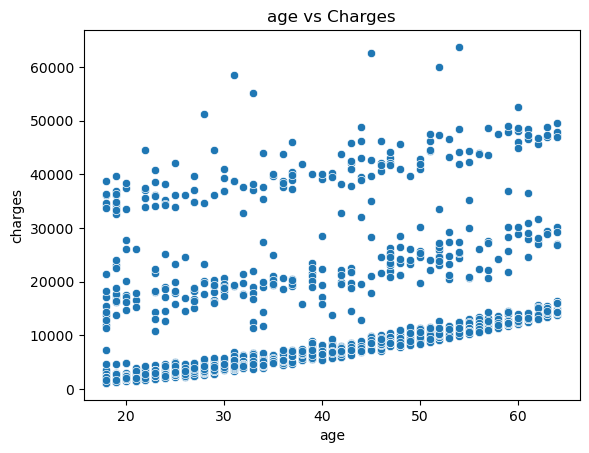

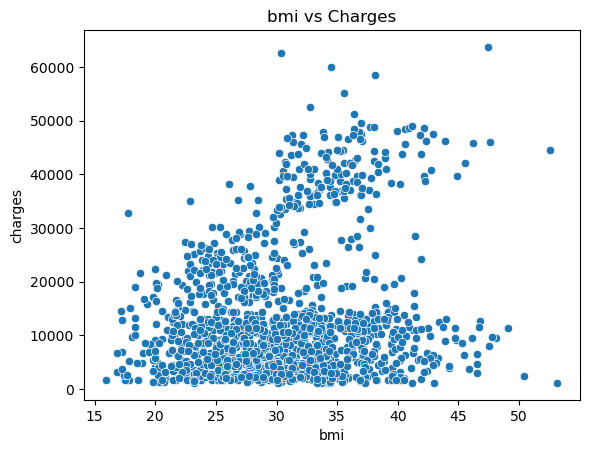

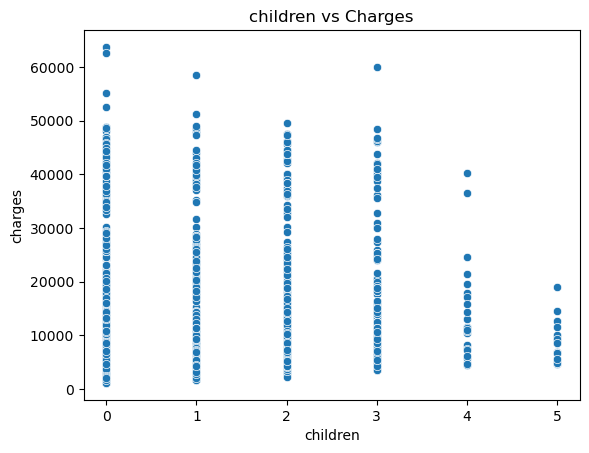

In [9]:
num_col = ["age", "bmi", "children"]

for col in num_col:
    sns.scatterplot(
        data=df,
        x=col,
        y="charges"
    )

    plt.title(f"{col} vs Charges")
    plt.show()

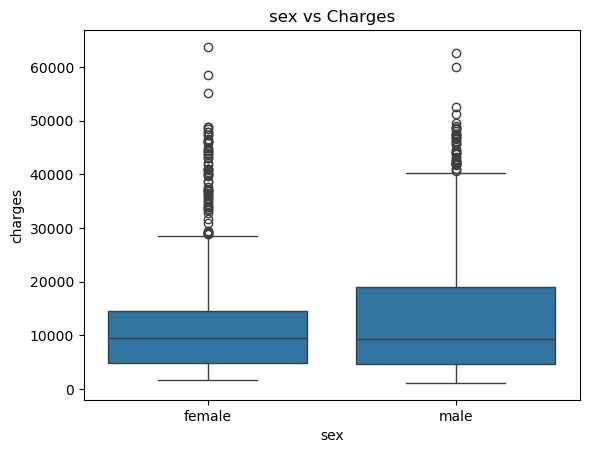

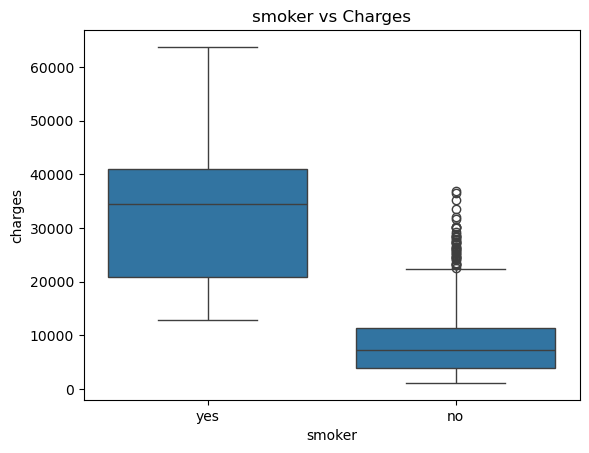

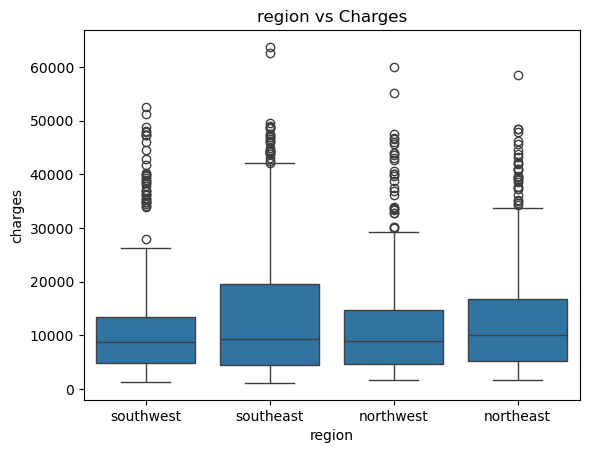

In [10]:
cat_col = ["sex", "smoker", "region"]

for col in cat_col:
    sns.boxplot(
        data=df,
        x=col,
        y="charges"
    )

    plt.title(f"{col} vs Charges")
    plt.show()

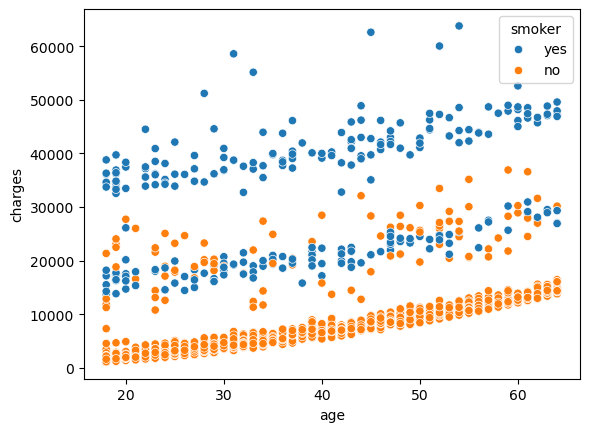

In [11]:
sns.scatterplot(
    data=df,
    x="age",
    y="charges",
    hue="smoker"
)
plt.show()

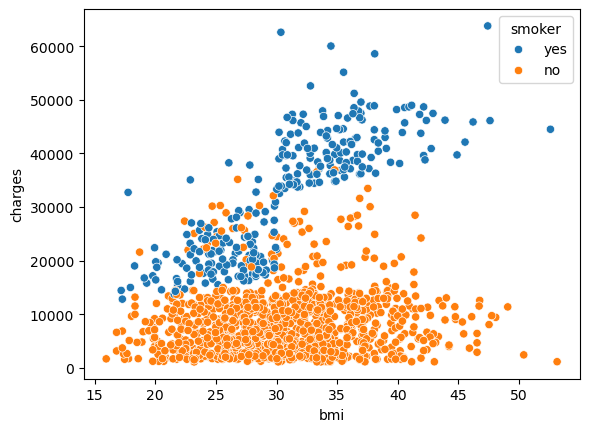

In [12]:
sns.scatterplot(
    data=df,
    x="bmi",
    y="charges",
    hue="smoker"
)
plt.show()

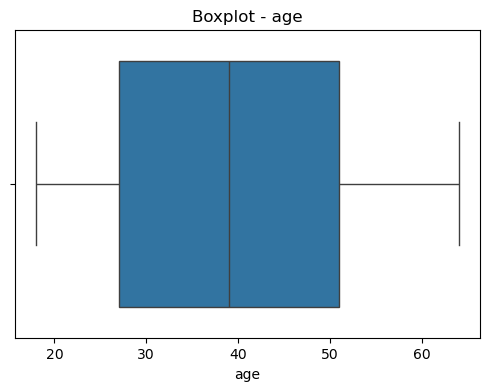

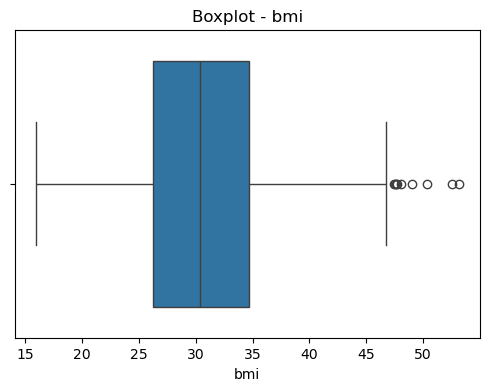

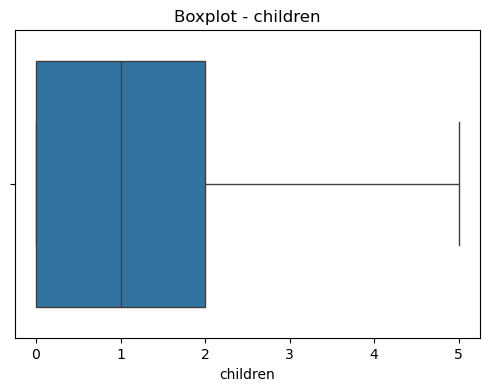

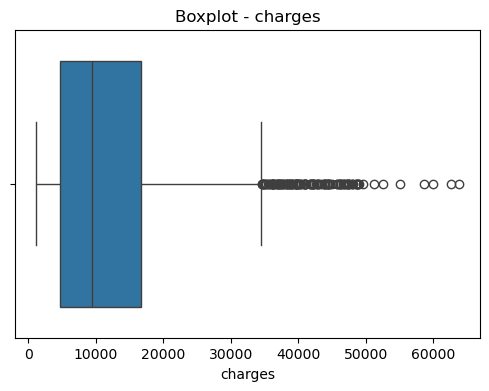

In [13]:
num_col=df.select_dtypes(include=["int64","float64"]).columns

for col in num_col:

    plt.figure(figsize=(6, 4))

    sns.boxplot(x=df[col])

    plt.title(f"Boxplot - {col}")
    plt.show()

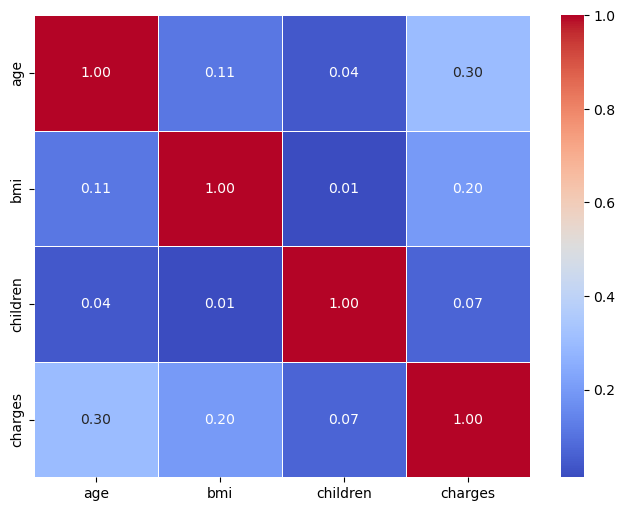

In [14]:
corr_col=df.corr(numeric_only=True)
plt.figure(figsize=(8, 6))
sns.heatmap(corr_col, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)
plt.show()

In [15]:
df[(df["bmi"]>45)&(df["age"]>30)].head(10)

,age,sex,bmi,children,smoker,region,charges
116,58,male,49.06,0,no,southeast,11381.32540
286,46,female,48.07,2,no,northeast,9432.92530
401,47,male,47.52,1,no,southeast,8083.91980
438,52,female,46.75,5,no,southeast,12592.53450
454,32,male,46.53,2,no,southeast,4686.38870
543,54,female,47.41,0,yes,southeast,63770.42801
547,54,female,46.70,2,no,southwest,11538.42100
549,43,female,46.20,0,yes,southeast,45863.20500
582,39,male,45.43,2,no,southeast,6356.27070
660,37,male,46.53,3,no,southeast,6435.62370


In [16]:
def show_outliers(df,col,col_ouliers):
    q1=df[col_ouliers].quantile(0.25)
    q3=df[col_ouliers].quantile(0.75)

    iqr=q3-q1

    lower=q1-1.5*iqr
    upper=q3+1.5*iqr

    outliers = df[
        (df[col_ouliers] < lower) |
        (df[col_ouliers] > upper)
    ]

    print(f"\nOutliers in: {col_ouliers}")
    print(f"Lower Bound: {lower}")
    print(f"Upper Bound: {upper}")
    print(f"Number of Outliers: {len(outliers)}")

    print("\nOutlier Values:")
    print(outliers[col + [col_ouliers]])
    return outliers


fare_outliers = show_outliers(
    df,
    ["age","sex","smoker","charges"],
    "bmi"
)


Outliers in: bmi
Lower Bound: 13.674999999999994
Upper Bound: 47.31500000000001
Number of Outliers: 9

Outlier Values:
      age     sex smoker      charges    bmi
116    58    male     no  11381.32540  49.06
286    46  female     no   9432.92530  48.07
401    47    male     no   8083.91980  47.52
543    54  female    yes  63770.42801  47.41
847    23    male     no   2438.05520  50.38
860    37  female    yes  46113.51100  47.60
1047   22    male    yes  44501.39820  52.58
1088   52    male     no   9748.91060  47.74
1317   18    male     no   1163.46270  53.13


In [17]:
fare_outliers = show_outliers(
    df,
    ["age","sex","smoker","bmi"],
    "charges"
)
print(fare_outliers[fare_outliers["smoker"]=="no"])
print("\n")
print(fare_outliers[fare_outliers["smoker"]=="yes"].head(5))


Outliers in: charges
Lower Bound: -13120.716174999998
Upper Bound: 34524.777625
Number of Outliers: 139

Outlier Values:
      age     sex smoker     bmi      charges
14     27    male    yes  42.130  39611.75770
19     30    male    yes  35.300  36837.46700
23     34  female    yes  31.920  37701.87680
29     31    male    yes  36.300  38711.00000
30     22    male    yes  35.600  35585.57600
...   ...     ...    ...     ...          ...
1300   45    male    yes  30.360  62592.87309
1301   62    male    yes  30.875  46718.16325
1303   43    male    yes  27.800  37829.72420
1313   19  female    yes  34.700  36397.57600
1323   42  female    yes  40.370  43896.37630

[139 rows x 5 columns]
      age     sex    bmi  children smoker     region      charges
242    55  female  26.80         1     no  southwest  35160.13457
1012   61  female  33.33         4     no  southeast  36580.28216
1206   59  female  34.80         2     no  southwest  36910.60803


    age     sex    bmi  children smo

In [18]:
def extract_new_feature(r):
    b=r["bmi"]
    s=r["smoker"]

    if b>=30 and s=="yes":
        return 1
    else:
        return 0 

df["risk"]=df.apply(extract_new_feature,axis=1)
df["risk"].value_counts()

risk
0    1192
1     145
Name: count, dtype: int64

In [19]:
x = df.drop("charges", axis=1)
y = df["charges"]

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    shuffle=True
)
print(f"Shape X_train: {x_train.shape}")
print(f"Shape X_test: {x_test.shape}")

Shape X_train: (1069, 7)
Shape X_test: (268, 7)


In [20]:
numerical_cols = x_train.select_dtypes(include=["int64", "float64"]).columns.tolist()
categorical_cols = x_train.select_dtypes(include=["object", "category"]).columns.tolist()

print(f"Numerical columns: {numerical_cols}")
print("\n")
print(f"Categorical columns: {categorical_cols}")

Numerical columns: ['age', 'bmi', 'children', 'risk']


Categorical columns: ['sex', 'smoker', 'region']


In [21]:
numerical_pipline=Pipeline([
    ("imputer",CustomNumericalImputer(stratigy="median")),
    ("scal",RobustScaler())
])

categorical_pipline=Pipeline([
    ("imputer",SimpleImputer(strategy="most_frequent")),
    ("onehot",OneHotEncoder(handle_unknown="ignore",drop="first",sparse_output=False))
])

preprocess=ColumnTransformer([
    ("num",numerical_pipline,numerical_cols),
    ("cat",categorical_pipline,categorical_cols)
],remainder="drop")

In [22]:
def evaluation(name,model,x_test,y_test):
    y_pred=model.predict(x_test)

    score={
        "Model":name,
        "MAE":mean_absolute_error(y_test,y_pred),
        "MSE":mean_squared_error(y_test,y_pred),
        "RMSE":np.sqrt(mean_squared_error(y_test,y_pred)),
        "R2": r2_score(y_test, y_pred)
    }
    return score,y_pred

In [23]:
full_pipline=Pipeline([
    ("process",preprocess),
    ("model",LinearRegression())
])

full_pipline.fit(x_train,y_train)
log_score,log_pred=evaluation("LogisticRegression",full_pipline,x_test,y_test)
log_score

{'Model': 'LogisticRegression',
 'MAE': 2391.5618180969923,
 'MSE': 17333984.549784143,
 'RMSE': 4163.410206763699,
 'R2': 0.905668503294089}

In [24]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    "model__fit_intercept": [True, False]
}

grid = GridSearchCV(
    estimator=full_pipline,
    param_grid=param_grid,
    cv=5,
    scoring="r2",
    n_jobs=-1
)

grid.fit(x_train, y_train)

GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('process',
                                        ColumnTransformer(transformers=[('num',
                                                                         Pipeline(steps=[('imputer',
                                                                                          CustomNumericalImputer()),
                                                                                         ('scal',
                                                                                          RobustScaler())]),
                                                                         ['age',
                                                                          'bmi',
                                                                          'children',
                                                                          'risk']),
                                                                        ('cat',
                                                                         Pipeline(steps=[('imputer',
                                                                                          SimpleImputer(strategy='most_frequent')),
                                                                                         ('onehot',
                                                                                          OneHotEncoder(drop='first',
                                                                                                        handle_unknown='ignore',
                                                                                                        sparse_output=False))]),
                                                                         ['sex',
                                                                          'smoker',
                                                                          'region'])])),
                                       ('model', LinearRegression())]),
             n_jobs=-1, param_grid={'model__fit_intercept': [True, False]},
             scoring='r2')

In [25]:
print("Best Parameters:", grid.best_params_)
print("Best CV Score:", grid.best_score_)

Best Parameters: {'model__fit_intercept': True}
Best CV Score: 0.8471294870646524


In [26]:
log_score, log_pred = evaluation(
    "Linear Regression",
    grid.best_estimator_,
    x_test,
    y_test
)

print(log_score)

{'Model': 'Linear Regression', 'MAE': 2391.5618180969923, 'MSE': 17333984.549784143, 'RMSE': 4163.410206763699, 'R2': 0.905668503294089}


In [27]:
best_model = grid.best_estimator_

y_train_pred = best_model.predict(x_train)
y_test_pred = best_model.predict(x_test)

train_r2 = r2_score(y_train, y_train_pred)
test_r2 = r2_score(y_test, y_test_pred)

train_mae = mean_absolute_error(y_train, y_train_pred)
test_mae = mean_absolute_error(y_test, y_test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred))

print("Train R2:", train_r2)
print("Test R2:", test_r2)
print("CV R2:", grid.best_score_)

print("\nTrain MAE:", train_mae)
print("Test MAE:", test_mae)

print("\nTrain RMSE:", train_rmse)
print("Test RMSE:", test_rmse)

r2_gap = train_r2 - test_r2
print("\nR2 Gap:", r2_gap)

if r2_gap > 0.10:
    print("Overfitting")
else:
    print("No Overfitting ")

Train R2: 0.8485577094282314
Test R2: 0.905668503294089
CV R2: 0.8471294870646524

Train MAE: 2523.216136202603
Test MAE: 2391.5618180969923

Train RMSE: 4553.5339304585395
Test RMSE: 4163.410206763699

R2 Gap: -0.0571107938658576
No Overfitting 


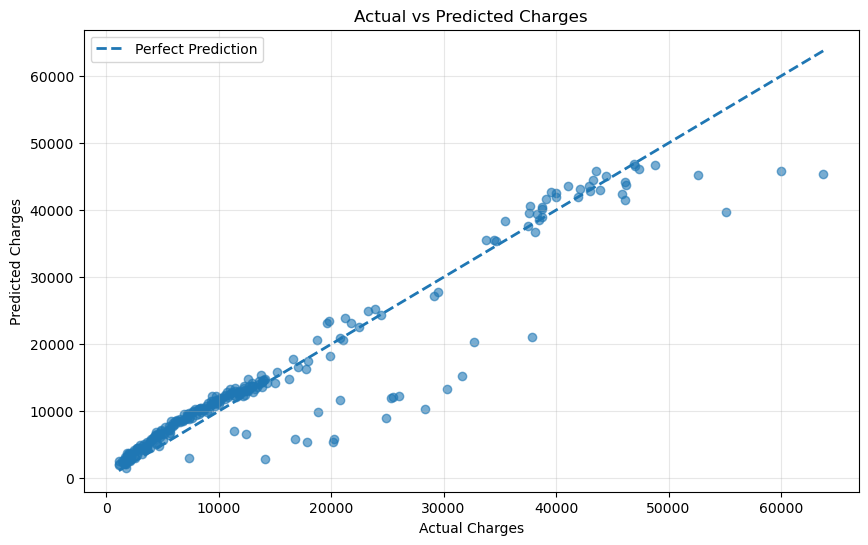

In [ ]:
import matplotlib.pyplot as plt


y_test_pred = best_model.predict(x_test)

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    y_test_pred,
    alpha=0.6
)

min_val = min(y_test.min(), y_test_pred.min())
max_val = max(y_test.max(), y_test_pred.max())

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--",
    linewidth=2,
    label="Perfect Prediction"
)

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Charges")

plt.legend()
plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
import joblib

MODEL_PATH = "Medical_best_pipeline.pkl"

joblib.dump(best_model, MODEL_PATH)

print(f"Saved best pipeline to: {MODEL_PATH}")

loaded_pipeline = joblib.load(MODEL_PATH)

print("Pipeline loaded successfully.")

Saved best pipeline to: Medical_best_pipeline.pkl
Pipeline loaded successfully.
